# Lung Cancer Prediction with Logistic Regression

**Author:** Miguel Estrada

## Project objective
Explore the lung cancer dataset and build a **Multinomial Logistic Regression** classification model to predict the lung cancer severity level (`Level`: Low, Medium, High) from patient demographic, symptom, and environmental risk variables.

> **Important:** This is an educational data-analysis project. It does not replace professional clinical diagnosis. The dataset's relationships and predictions should not be interpreted as definitive clinical decisions.

## Notebook outline
1. Load and inspect the data
2. Data quality checks
3. Exploratory data analysis (EDA)
4. Prepare the target and predictor variables
5. Encode categorical variables and scale numerical variables
6. Train Logistic Regression
7. Evaluate classification performance
8. Interpret coefficients and feature importances
9. Summarize findings and limitations

The notebook expects `cancer.csv` to be in the same folder.


In [10]:
# Imports
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    PrecisionRecallDisplay,
)

sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

In [11]:
# 1. Load the dataset
data = pd.read_csv("cancer.csv")

print(f"Dataset shape: {data.shape[0]:,} rows × {data.shape[1]} columns")
display(data.head())

Dataset shape: 1,000 rows × 26 columns


,index,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,Obesity,Smoking,Passive Smoker,Chest Pain,Coughing of Blood,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,0,P1,33,1,2,4,5,4,3,2,2,4,3,2,2,4,3,4,2,2,3,1,2,3,4,Low
1,1,P10,17,1,3,1,5,3,4,2,2,2,2,4,2,3,1,3,7,8,6,2,1,7,2,Medium
2,2,P100,35,1,4,5,6,5,5,4,6,7,2,3,4,8,8,7,9,2,1,4,6,7,2,High
3,3,P1000,37,1,7,7,7,7,6,7,7,7,7,7,7,8,4,2,3,1,4,5,6,7,5,High
4,4,P101,46,1,6,8,7,7,7,6,7,7,8,7,7,9,3,2,4,1,4,2,4,2,3,High


In [12]:
# 2. Dataset overview and data quality
display(data.info())

print("\\nMissing values by column:")
display(data.isna().sum().to_frame("Missing values"))

print(f"\\nExact duplicate rows: {data.duplicated().sum():,}")
print("\\nTarget distribution:")
display(data["Level"].value_counts(dropna=False).to_frame("Count"))
display(
    (data["Level"].value_counts(normalize=True, dropna=False) * 100)
    .round(2).to_frame("Percentage")
)

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   index                     1000 non-null   int64
 1   Patient Id                1000 non-null   str  
 2   Age                       1000 non-null   int64
 3   Gender                    1000 non-null   int64
 4   Air Pollution             1000 non-null   int64
 5   Alcohol use               1000 non-null   int64
 6   Dust Allergy              1000 non-null   int64
 7   OccuPational Hazards      1000 non-null   int64
 8   Genetic Risk              1000 non-null   int64
 9   chronic Lung Disease      1000 non-null   int64
 10  Balanced Diet             1000 non-null   int64
 11  Obesity                   1000 non-null   int64
 12  Smoking                   1000 non-null   int64
 13  Passive Smoker            1000 non-null   int64
 14  Chest Pain                1000 non-null   int64
 15 

None

\nMissing values by column:


,Missing values
index,0
Patient Id,0
Age,0
Gender,0
Air Pollution,0
Alcohol use,0
Dust Allergy,0
OccuPational Hazards,0
Genetic Risk,0
chronic Lung Disease,0


\nExact duplicate rows: 0
\nTarget distribution:


,Count
Level,
High,365
Medium,332
Low,303


,Percentage
Level,
High,36.5
Medium,33.2
Low,30.3


In [13]:
data["Level"].value_counts(normalize=True, dropna=False)

Level
High      0.365
Medium    0.332
Low       0.303
Name: proportion, dtype: float64

In [14]:
# Validate the expected target labels and inspect categorical values
target_labels = set(data["Level"].dropna().unique())
expected_labels = {"High", "Medium", "Low"}

if not target_labels.issubset(expected_labels):
    raise ValueError(f"Unexpected lung cancer labels: {target_labels}")

categorical_columns = data.select_dtypes(include=["object", "category"]).columns.tolist()
numerical_columns = data.select_dtypes(include=np.number).columns.tolist()

print("Categorical columns:", categorical_columns)
print("Numerical columns:", numerical_columns)

for column in categorical_columns:
    print(f"\\n{column}:")
    display(data[column].value_counts(dropna=False).to_frame("Count"))

Categorical columns: ['Patient Id', 'Level']
Numerical columns: ['index', 'Age', 'Gender', 'Air Pollution', 'Alcohol use', 'Dust Allergy', 'OccuPational Hazards', 'Genetic Risk', 'chronic Lung Disease', 'Balanced Diet', 'Obesity', 'Smoking', 'Passive Smoker', 'Chest Pain', 'Coughing of Blood', 'Fatigue', 'Weight Loss', 'Shortness of Breath', 'Wheezing', 'Swallowing Difficulty', 'Clubbing of Finger Nails', 'Frequent Cold', 'Dry Cough', 'Snoring']
\nPatient Id:


C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_17664\377792172.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = data.select_dtypes(include=["object", "category"]).columns.tolist()


,Count
Patient Id,
P1,1
P10,1
P100,1
P1000,1
P101,1
...,...
P995,1
P996,1
P997,1


\nLevel:


,Count
Level,
High,365
Medium,332
Low,303


## Exploratory Data Analysis (EDA)

The following steps describe the sample and inspect how variables are distributed across lung cancer severity levels (`Low`, `Medium`, `High`).


## Model preparation

The target is mapped explicitly rather than using `LabelEncoder`:

| Original target value | Numeric code | Meaning |
|---|---:|---|
| `Low` | 0 | Low lung cancer risk / severity level |
| `Medium` | 1 | Medium lung cancer risk / severity level |
| `High` | 2 | High lung cancer risk / severity level |

ID and index columns (`Patient Id`, `index`) are dropped from predictor features. Categorical predictor variables (if any) are handled with **One-Hot Encoding**. Numerical variables are standardized using statistics learned from the training set.

Preprocessing is placed inside a Scikit-learn `Pipeline` to prevent data leakage from the test data.


In [15]:
# 6. Split features and target
# Explicitly document the target encoding
target_mapping = {"Low": 0, "Medium": 1, "High": 2}
y = data["Level"].map(target_mapping).astype(int)

# Drop target column and non-predictive identifiers (Patient Id, index)
drop_cols = [col for col in ["Level", "Patient Id", "index"] if col in data.columns]
X = data.drop(columns=drop_cols).copy()

# Identify feature types from X only
categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

print("Target encoding:")
print(target_mapping)
print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows:  {len(X_test):,}")


Target encoding:
{'Low': 0, 'Medium': 1, 'High': 2}
\nNumeric features: ['index', 'Age', 'Gender', 'Air Pollution', 'Alcohol use', 'Dust Allergy', 'OccuPational Hazards', 'Genetic Risk', 'chronic Lung Disease', 'Balanced Diet', 'Obesity', 'Smoking', 'Passive Smoker', 'Chest Pain', 'Coughing of Blood', 'Fatigue', 'Weight Loss', 'Shortness of Breath', 'Wheezing', 'Swallowing Difficulty', 'Clubbing of Finger Nails', 'Frequent Cold', 'Dry Cough', 'Snoring']
Categorical features: ['Patient Id']
Training rows: 800
Testing rows:  200


C:\Users\Miguel Estrada\AppData\Local\Temp\ipykernel_17664\2318222208.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include=["object", "category"]).columns.tolist()


In [16]:
# 7. Preprocessing and Logistic Regression pipeline
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", drop="first")),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42,
    )),
])

model.fit(X_train, y_train)
print("Logistic Regression model trained successfully.")

Logistic Regression model trained successfully.


In [23]:
# 8. Predict labels and probabilities
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)

print("Predicted label codes:", sorted(np.unique(y_pred)))
print(f"Predicted probabilities shape: {y_proba.shape} (probabilities for [Low (0), Medium (1), High (2)])")


Predicted label codes: [np.int64(0), np.int64(1), np.int64(2)]
Probability values represent the model-estimated probability of target code 1 (Yes).


C:\Users\Miguel Estrada\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
C:\Users\Miguel Estrada\AppData\Roaming\Python\Python314\site-packages\sklearn\preprocessing\_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


In [27]:
# 9. Classification metrics
metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced accuracy",
        "Precision (macro)",
        "Recall (macro)",
        "F1-score (macro)",
        "Precision (weighted)",
        "Recall (weighted)",
        "F1-score (weighted)",
        "ROC-AUC (OvR, macro)",
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        balanced_accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, average="macro", zero_division=0),
        recall_score(y_test, y_pred, average="macro", zero_division=0),
        f1_score(y_test, y_pred, average="macro", zero_division=0),
        precision_score(y_test, y_pred, average="weighted", zero_division=0),
        recall_score(y_test, y_pred, average="weighted", zero_division=0),
        f1_score(y_test, y_pred, average="weighted", zero_division=0),
        roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro"),
    ],
})

display(metrics.round(4))
print("\nClassification report (0 = Low, 1 = Medium, 2 = High):")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1, 2],
    target_names=["Low (0)", "Medium (1)", "High (2)"],
    zero_division=0,
))


ValueError: Target is multiclass but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted'].

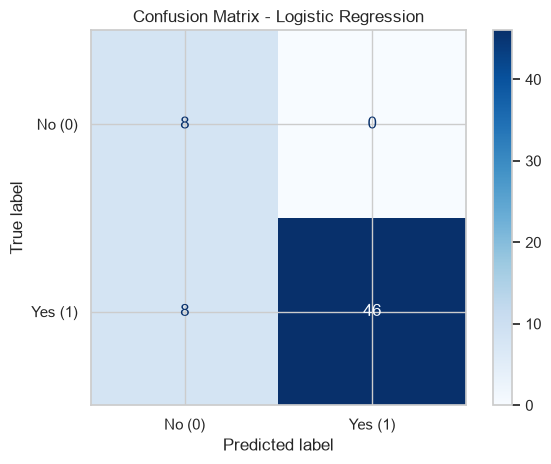

Confusion matrix layout:
Rows = actual labels; columns = predicted labels.
TN (top-left), FP (top-right), FN (bottom-left), TP (bottom-right).


In [ ]:
# 10. Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low (0)", "Medium (1)", "High (2)"],
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix - Multiclass Logistic Regression")
plt.tight_layout()
plt.show()

print("Confusion matrix layout:")
print("Rows = actual labels; columns = predicted labels.")


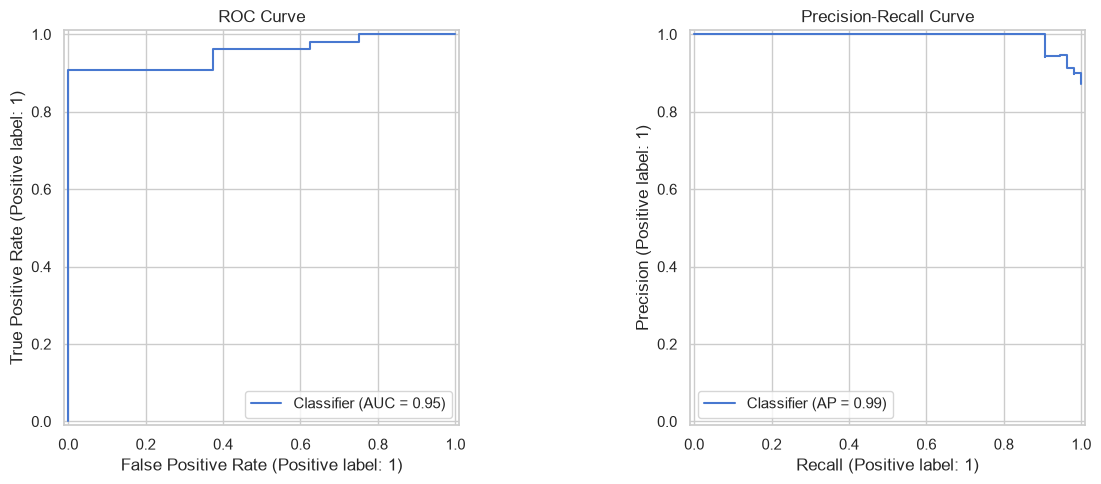

In [ ]:
# 11. ROC and Precision-Recall curves (One-vs-Rest for multiclass)
from sklearn.preprocessing import label_binarize

classes = [0, 1, 2]
class_names = ["Low (0)", "Medium (1)", "High (2)"]
y_test_bin = label_binarize(y_test, classes=classes)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for i, class_name in enumerate(class_names):
    RocCurveDisplay.from_predictions(
        y_test_bin[:, i],
        y_proba[:, i],
        name=f"ROC {class_name}",
        ax=axes[0],
    )
axes[0].set_title("Multiclass ROC Curves (One-vs-Rest)")

for i, class_name in enumerate(class_names):
    PrecisionRecallDisplay.from_predictions(
        y_test_bin[:, i],
        y_proba[:, i],
        name=f"PR {class_name}",
        ax=axes[1],
    )
axes[1].set_title("Multiclass Precision-Recall Curves (One-vs-Rest)")

plt.tight_layout()
plt.show()


## Coefficients and feature importance

Multinomial Logistic Regression models log-odds for each class relative to the baseline/other classes (One-vs-Rest formulation).
- **Class-specific coefficient:** A positive coefficient for a class indicates that higher values of the standardized feature increase the likelihood of that specific cancer severity level.
- **Mean absolute coefficient:** The average absolute magnitude across all classes summarizes overall feature influence in the model.


In [ ]:
# 12. Extract transformed feature names and coefficients
fitted_preprocessor = model.named_steps["preprocessor"]
fitted_classifier = model.named_steps["classifier"]

feature_names = fitted_preprocessor.get_feature_names_out()
class_labels = ["Low (0)", "Medium (1)", "High (2)"]

# Build coefficient table for each class
coef_data = {"Encoded feature": feature_names}
for i, label in enumerate(class_labels):
    coef_data[f"Coefficient ({label})"] = fitted_classifier.coef_[i]

coefficient_analysis = pd.DataFrame(coef_data)
coef_cols = [f"Coefficient ({label})" for label in class_labels]
coefficient_analysis["Mean absolute coefficient"] = coefficient_analysis[coef_cols].abs().mean(axis=1)

coefficient_analysis = coefficient_analysis.sort_values(
    "Mean absolute coefficient", ascending=False
).reset_index(drop=True)

display(coefficient_analysis.round(4))


,Encoded feature,Coefficient,Absolute coefficient,Odds ratio,Relative coefficient magnitude (%)
0,numeric__FATIGUE,1.2480,1.2480,3.4834,11.4868
1,numeric__CHRONIC DISEASE,1.2178,1.2178,3.3798,11.2088
2,numeric__SWALLOWING DIFFICULTY,1.1467,1.1467,3.1478,10.5542
3,numeric__ALLERGY,1.0895,1.0895,2.9728,10.0279
4,numeric__PEER_PRESSURE,1.0378,1.0378,2.8229,9.5515
5,numeric__ALCOHOL CONSUMING,0.9618,0.9618,2.6164,8.8522
6,numeric__COUGHING,0.9046,0.9046,2.4708,8.3255
7,numeric__YELLOW_FINGERS,0.7300,0.7300,2.0751,6.7191
8,numeric__ANXIETY,0.6983,0.6983,2.0104,6.4272
9,numeric__SMOKING,0.5693,0.5693,1.7670,5.2396


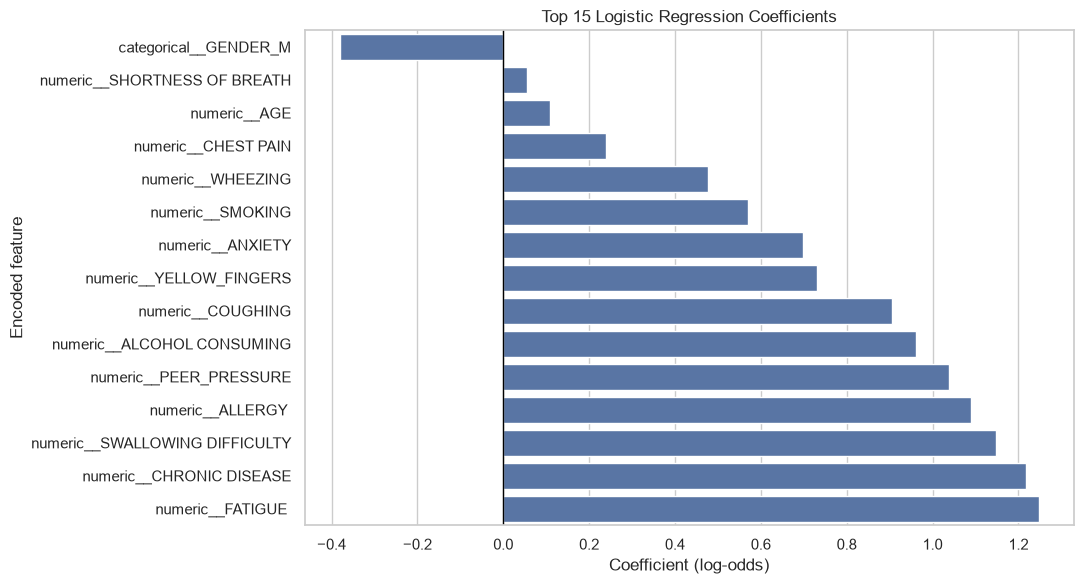

In [ ]:
# 13. Plot the largest coefficient magnitudes across classes
top_n = min(20, len(coefficient_analysis))
top_features = coefficient_analysis.head(top_n).sort_values("Mean absolute coefficient", ascending=True)

plt.figure(figsize=(11, max(6, top_n * 0.35)))
sns.barplot(data=top_features, x="Mean absolute coefficient", y="Encoded feature", color="#4C72B0")
plt.title(f"Top {top_n} Features by Mean Absolute Coefficient Magnitude")
plt.xlabel("Mean Absolute Coefficient (Across Classes)")
plt.ylabel("Encoded feature")
plt.tight_layout()
plt.show()


In [ ]:
# 14. Show the exact category encoding and reference categories
if categorical_features:
    ohe = fitted_preprocessor.named_transformers_["categorical"].named_steps["onehot"]
    category_encoding = []

    for feature, categories in zip(categorical_features, ohe.categories_):
        dropped = ohe.drop_idx_
        drop_index = None if dropped is None else dropped[categorical_features.index(feature)]
        reference = None if drop_index is None else categories[drop_index]

        for category in categories:
            category_encoding.append({
                "Original column": feature,
                "Original category": category,
                "Encoded column": (
                    f"categorical__{feature}_{category}"
                    if category != reference
                    else "Reference category (all dummy columns = 0)"
                ),
                "Reference category": reference,
            })

    category_encoding_table = pd.DataFrame(category_encoding)
    display(category_encoding_table)
else:
    print("No categorical predictor features were encoded (all predictors are numerical).")

print("\nTarget label mapping:")
display(pd.DataFrame([
    {"Original target": "Low", "Encoded value": 0, "Description": "Low lung cancer risk / severity level"},
    {"Original target": "Medium", "Encoded value": 1, "Description": "Medium lung cancer risk / severity level"},
    {"Original target": "High", "Encoded value": 2, "Description": "High lung cancer risk / severity level"},
]))


,Original column,Original category,Encoded column,Reference category
0,GENDER,F,Reference category (all dummy columns = 0),F
1,GENDER,M,categorical__GENDER_M,F


\nTarget label mapping:


,Original target,Encoded value,Description
0,No,0,Dataset label indicates no depression
1,Yes,1,Dataset label indicates depression


## Conclusions and interpretation

Use the metric table, confusion matrix, and coefficient table above to describe the model's performance:

- Review **Precision, Recall, and F1-score across all 3 levels (Low, Medium, High)** to evaluate how well each class is recognized.
- Compare accuracy with balanced accuracy and weighted metrics.
- Examine the confusion matrix to check for misclassifications between adjacent risk tiers (e.g., Low vs Medium or Medium vs High).
- Review feature importances to see which symptoms and exposures (e.g., Air Pollution, Smoking, Genetic Risk, Coughing of Blood) have the strongest association with cancer severity levels.

## Limitations and responsible use

- The dataset is observational and should not be used as a standalone diagnostic tool.
- Logistic Regression models linear relationships with log-odds; potential complex interactions between environmental factors and genetics can be explored further.
- Always validate on external patient cohorts before drawing clinical conclusions.

**Project author:** Miguel Estrada
